In [104]:
# Monta Google Drive para leer los CSV (versión archivada: hoy los datos están en data/raw)
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [105]:
#@title Se importan las librerías
#Realizamos todas las importaciónes de librerías para el correcto funcionamiento
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

#Modelos de entrenamiento
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [106]:
#@title Cargar los datos:
# # Cargar los datos csv
# data_list = []
# for archivo in ["/content/drive/MyDrive/DatosNotas/matematicas.csv",
#                 "/content/drive/MyDrive/DatosNotas/ingles.csv",
#                 "/content/drive/MyDrive/DatosNotas/Fisica.csv",
#                 "/content/drive/MyDrive/DatosNotas/C_SOCIALES.csv",
#                 "/content/drive/MyDrive/DatosNotas/C_Naturales.csv"
#                 ]:
#     #Se guardan los datos en una variable en este caso "data"
#     data = pd.read_csv(archivo)
#     data_list.append(data)

# Cargar los datos csv
data_list = []
for archivo in ["/content/drive/MyDrive/DatosNotas2/matematicas.csv",
                "/content/drive/MyDrive/DatosNotas2/ingles.csv",
                "/content/drive/MyDrive/DatosNotas2/Fisica.csv",
                "/content/drive/MyDrive/DatosNotas2/C_SOCIALES.csv",
                "/content/drive/MyDrive/DatosNotas2/C_Naturales.csv"
                ]:
    #Se guardan los datos en una variable en este caso "data"
    data = pd.read_csv(archivo)
    data_list.append(data)

El promedio es de :  0.48833443732980053


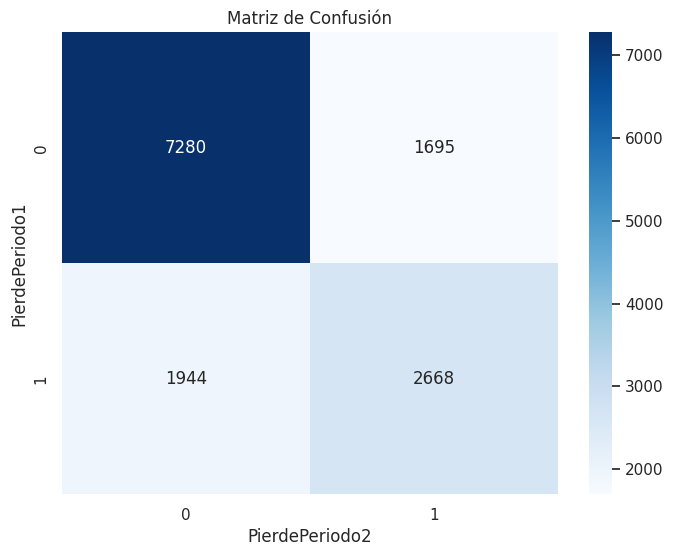

In [109]:
# Concatenar todos los DataFrames en uno solo
combined_data = pd.concat(data_list)

# Definir una función para calcular el promedio de ganadores
def calcular_promedio_ganadores(data):
    ganadores = data[(data['Periodo1'] >= 3) & (data['Periodo2'] >= 3)]
    total_estudiantes = len(data)
    promedio_ganadores = len(ganadores) / total_estudiantes
    return promedio_ganadores

# Calcular el promedio de ganadores
promedio = calcular_promedio_ganadores(combined_data)
print('El promedio es de : ', promedio)
# Calcular la matriz de confusión
matriz_confusion = pd.crosstab(combined_data['PierdePeriodo1'], combined_data['PierdePeriodo2'])

# Visualizar la matriz de confusión como un mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt="d", cmap="Blues")
plt.xlabel("PierdePeriodo2")
plt.ylabel("PierdePeriodo1")
plt.title("Matriz de Confusión")
plt.show()

In [110]:
# Definir las etiquetas verdaderas (ground truth) y las etiquetas predichas
ground_truth = combined_data['PierdePeriodo1']
predicted_labels = combined_data['PierdePeriodo2']

# Generar un informe de clasificación
report = classification_report(ground_truth, predicted_labels)

print("Informe de Clasificación:\n")
print(report)

Informe de Clasificación:

              precision    recall  f1-score   support

           0       0.79      0.81      0.80      8975
           1       0.61      0.58      0.59      4612

    accuracy                           0.73     13587
   macro avg       0.70      0.69      0.70     13587
weighted avg       0.73      0.73      0.73     13587



#Predicciónes realizadas sin validación(Con los mismos datos entrenados se realiza una predicción)

##Predicción Regresión Logistica

###Periodo 1:

In [ ]:
# @title Codigo Periodo 1:
#Codigo que contiene la logica para la realización de la predicción
# Separar los datos de entrada y salida
X_list = []
y_list = []

for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases
smote = SMOTE(sampling_strategy='auto')
X_resampled, y_resampled = smote.fit_resample(X, y)

# Entrenar el modelo de regresión logística en los datos equilibrados
model = LogisticRegression()
model.fit(X_resampled, y_resampled)
# Predecir los resultados
prediccion = model.predict(X)
prediccion

array([0, 0, 0, ..., 1, 0, 0])

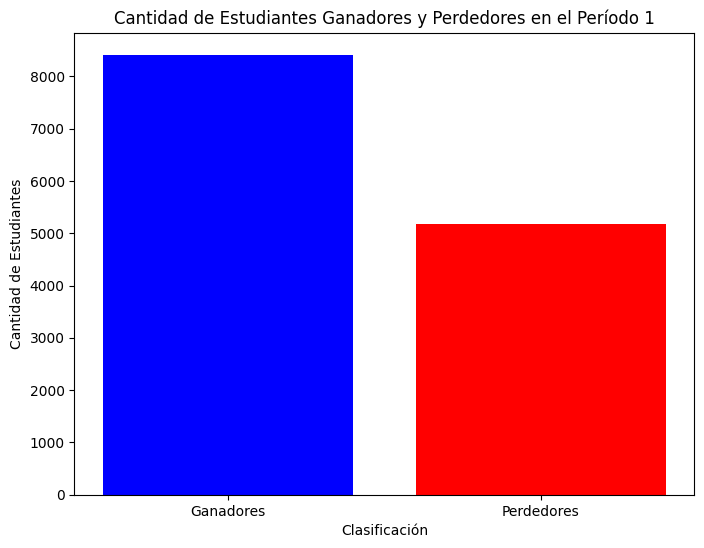


Cantidad de estudiantes que ganaron las materias en el periodo 1:  8414

Cantidad de estudiantes que perdieron las materias en el periodo 1:  5173


In [ ]:
# @title Grafica periodo 1:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores", "Perdedores"]
cantidad_estudiantes = [cantidad_ganadores, cantidad_perdedores]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(8, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1")

# Mostrar el gráfico de barras
plt.show()

# Imprimir los resultados
print()
print("Cantidad de estudiantes que ganaron las materias en el periodo 1: ", cantidad_ganadores)
print()
print("Cantidad de estudiantes que perdieron las materias en el periodo 1: ", cantidad_perdedores)

In [ ]:
# Separar los datos de entrada y salida
X_list = []
y_list = []

for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases
smote = SMOTE(sampling_strategy='auto')
X_resampled, y_resampled = smote.fit_resample(X, y)

# Separar los datos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.25, random_state=42)

# Entrenar el modelo de regresión logística en los datos de entrenamiento
model = LogisticRegression()
model.fit(X_train, y_train)

# Predecir los resultados
prediccion = model.predict(X_test)

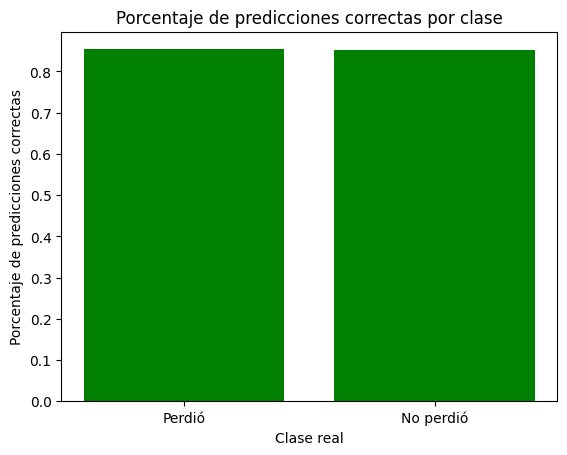

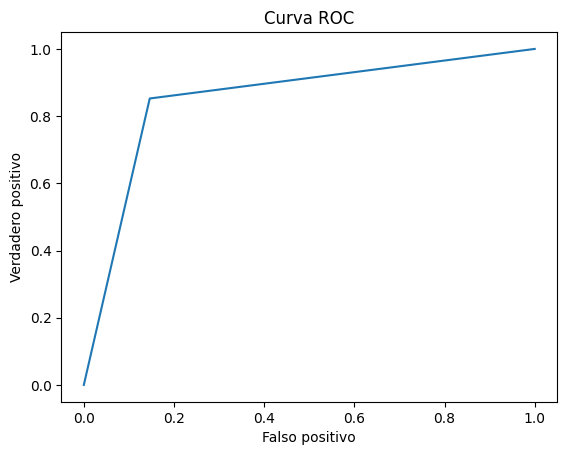

In [ ]:
# Generar la matriz de confusión
matriz_confusion = confusion_matrix(y_test, prediccion)

# Crear el gráfico de barras
plt.title("Porcentaje de predicciones correctas por clase")
plt.bar(["Perdió", "No perdió"], [matriz_confusion[0, 0] / sum(matriz_confusion[0]), matriz_confusion[1, 1] / sum(matriz_confusion[1])], color="green")
plt.xlabel("Clase real")
plt.ylabel("Porcentaje de predicciones correctas")
plt.show()

# Importar la librería sklearn.metrics
from sklearn.metrics import roc_curve, auc

# Calcular la curva ROC
fpr, tpr, thresholds = roc_curve(y_test, prediccion)

# Calcular el área bajo la curva ROC
auc = auc(fpr, tpr)

# Mostrar la curva ROC
plt.title("Curva ROC")
plt.plot(fpr, tpr)
plt.xlabel("Falso positivo")
plt.ylabel("Verdadero positivo")
plt.show()

In [ ]:
#@title Informe de Clasificación de entrenamiento del periodo 1:
# Calcular la matriz de confusión
cm = confusion_matrix(y, prediccion)

# Calcular otras métricas de evaluación
report = classification_report(y, prediccion)
print("Informe de Clasificación:")
print(report)

ValueError: ignored

In [ ]:
#@title Grafica de la Matriz de confusión de entrenamiento para el periodo 1:
# Crear una figura
plt.figure(figsize=(8, 6))

# Utilizar Seaborn para crear un mapa de calor (heatmap) de la matriz de confusión
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=["Ganadores (0)", "Perdedores (1)"],
            yticklabels=["Ganadores (0)", "Perdedores (1)"])

# Agregar etiquetas
plt.xlabel('Valores Predichos')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión')

# Mostrar el mapa de calor
plt.show()

NameError: ignored

<Figure size 800x600 with 0 Axes>

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de regresión logística en los datos equilibrados del "Periodo 1"
model = LogisticRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Evaluar el rendimiento en el "Periodo 2"

accuracy_periodo2 = accuracy_score(y_resampled_periodo2, prediccion_periodo2)
report_periodo2 = classification_report(y_resampled_periodo2, prediccion_periodo2)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2, prediccion_periodo2)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)

Accuracy en Periodo 2: 0.6047810060711188
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.59      0.68      0.63      9224
           1       0.62      0.53      0.57      9224

    accuracy                           0.60     18448
   macro avg       0.61      0.60      0.60     18448
weighted avg       0.61      0.60      0.60     18448



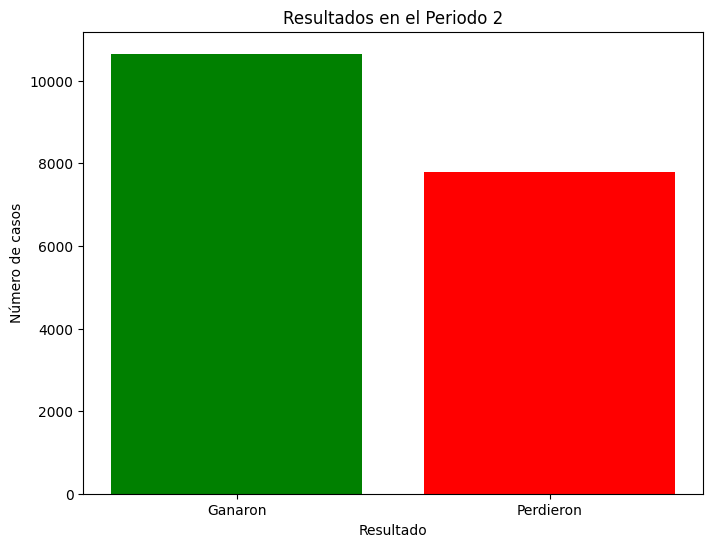

In [ ]:
# Contar cuántos ganaron y cuántos perdieron en el "Periodo 2"
ganaron_periodo2 = sum(prediccion_periodo2 == 0)
perdieron_periodo2 = sum(prediccion_periodo2 == 1)

# Crear una gráfica de barras
plt.figure(figsize=(8, 6))
plt.bar(['Ganaron', 'Perdieron'], [ganaron_periodo2, perdieron_periodo2], color=['green', 'red'])
plt.xlabel('Resultado')
plt.ylabel('Número de casos')
plt.title('Resultados en el Periodo 2')
plt.show()

In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de regresión logística en el conjunto de entrenamiento
model = LogisticRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion)
report_validacion = classification_report(y_valid, prediccion_validacion)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.5833333333333334
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.59      0.59      0.59       153
           1       0.58      0.57      0.57       147

    accuracy                           0.58       300
   macro avg       0.58      0.58      0.58       300
weighted avg       0.58      0.58      0.58       300



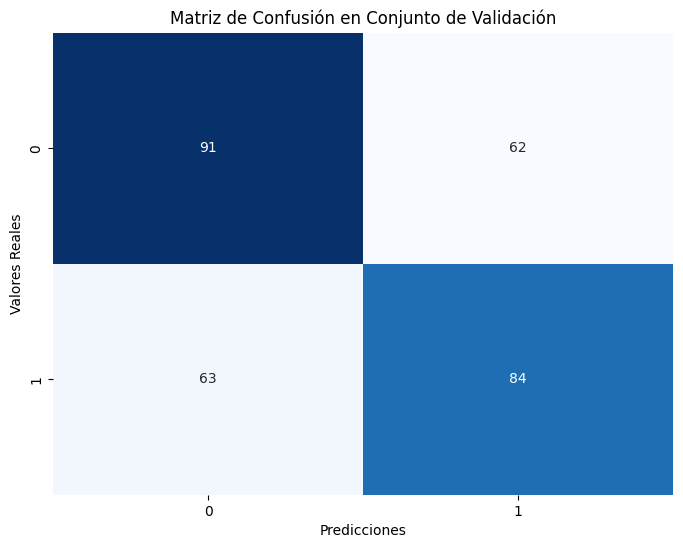

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

###Periodo 2:

In [ ]:
# @title Codigo Periodo 2:
#Codigo que contiene la logica para la realización de la predicción
# Separar los datos de entrada y salida
X_list = []
y_list = []

for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases
smote = SMOTE(sampling_strategy='auto')
X_resampled, y_resampled = smote.fit_resample(X, y)

# Entrenar el modelo de regresión logística en los datos equilibrados
model = LogisticRegression()
model.fit(X_resampled, y_resampled)
# Predecir los resultados
prediccion = model.predict(X)
prediccion

array([0, 0, 0, ..., 0, 1, 1])

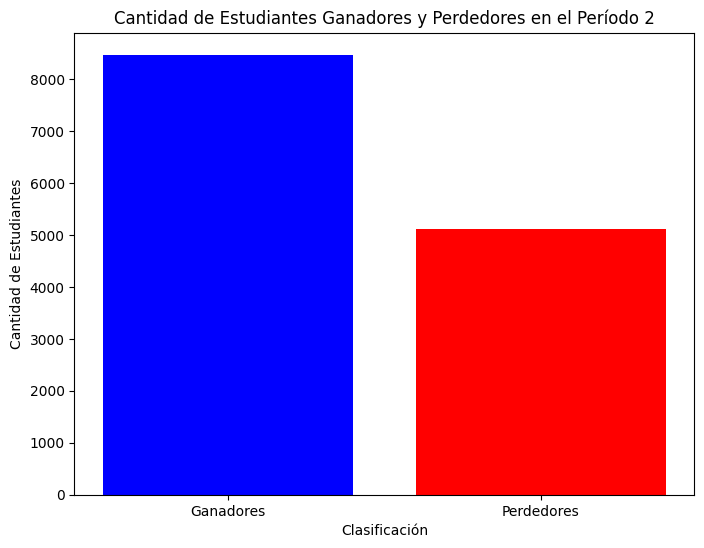


Cantidad de estudiantes que ganaron las materias en el periodo 2:  8473

Cantidad de estudiantes que perdieron las materias en el periodo 2:  5114


In [ ]:
# @title Grafica periodo 2:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores", "Perdedores"]
cantidad_estudiantes = [cantidad_ganadores, cantidad_perdedores]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(8, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 2")

# Mostrar el gráfico de barras
plt.show()

# Imprimir los resultados
print()
print("Cantidad de estudiantes que ganaron las materias en el periodo 2: ", cantidad_ganadores)
print()
print("Cantidad de estudiantes que perdieron las materias en el periodo 2: ", cantidad_perdedores)

In [ ]:
#@title Informe de Clasificación del periodo 2:
# Calcular la matriz de confusión
cm = confusion_matrix(y, prediccion)

# Calcular otras métricas de evaluación
report = classification_report(y, prediccion)
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.92      0.85      0.88      9224
           1       0.72      0.85      0.78      4363

    accuracy                           0.85     13587
   macro avg       0.82      0.85      0.83     13587
weighted avg       0.86      0.85      0.85     13587



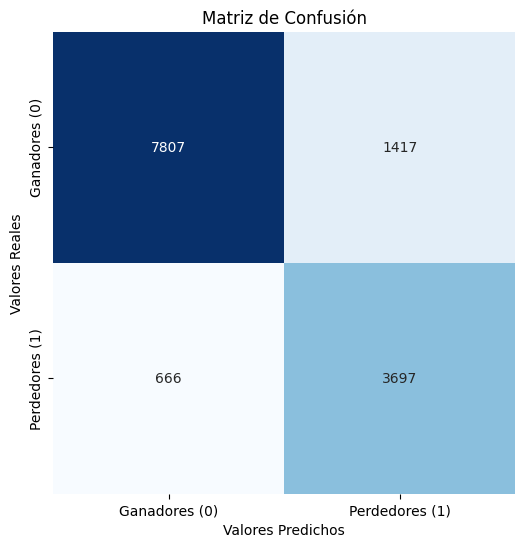

In [ ]:
#@title Grafica de la Matriz de confusión para el periodo 2:
# Crear una figura
plt.figure(figsize=(8, 6))

# Utilizar Seaborn para crear un mapa de calor (heatmap) de la matriz de confusión
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=["Ganadores (0)", "Perdedores (1)"],
            yticklabels=["Ganadores (0)", "Perdedores (1)"])

# Agregar etiquetas
plt.xlabel('Valores Predichos')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión')

# Mostrar el mapa de calor
plt.show()

###Periodo 3:

In [ ]:
# @title Codigo Periodo 3:
#Codigo que contiene la logica para la realización de la predicción
# Separar los datos de entrada y salida
X_list = []
y_list = []

for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data[["PierdePeriodo1","PierdePeriodo2"]]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = y.to_numpy()
y = y.ravel()
X = X[:5436]
# Aplicar SMOTE para abordar el desequilibrio de clases
smote = SMOTE(sampling_strategy='auto')
X_resampled, y_resampled = smote.fit_resample(X, y)

# Entrenar el modelo de regresión logística en los datos equilibrados
model = LogisticRegression()
model.fit(X_resampled, y_resampled)
# Predecir los resultados
prediccion = model.predict(X)
prediccion

array([1, 1, 1, ..., 0, 0, 1])

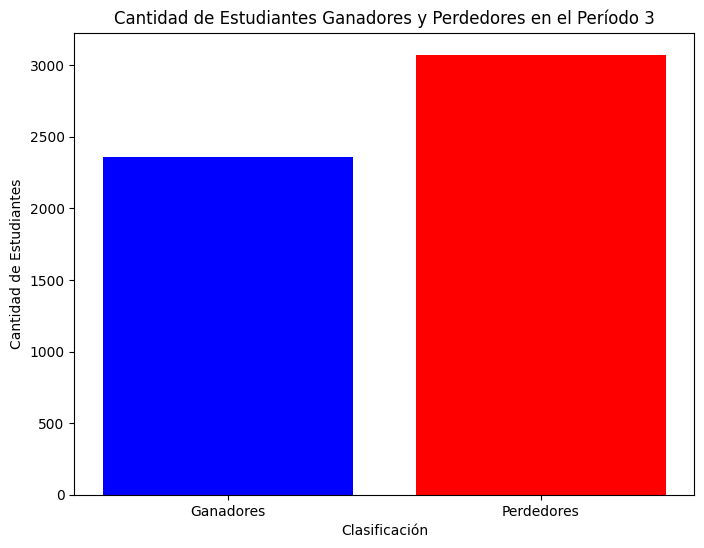


Cantidad de estudiantes que ganaron las materias en el periodo 3:  2362

Cantidad de estudiantes que perdieron las materias en el periodo 3:  3074


In [ ]:
# @title Grafica periodo 3:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores", "Perdedores"]
cantidad_estudiantes = [cantidad_ganadores, cantidad_perdedores]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(8, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 3")

# Mostrar el gráfico de barras
plt.show()

# Imprimir los resultados
print()
print("Cantidad de estudiantes que ganaron las materias en el periodo 3: ", cantidad_ganadores)
print()
print("Cantidad de estudiantes que perdieron las materias en el periodo 3: ", cantidad_perdedores)

In [ ]:
#@title Informe de Clasificación del periodo 3:
# Calcular la matriz de confusión
cm = confusion_matrix(y, prediccion)

# Calcular otras métricas de evaluación
report = classification_report(y, prediccion)
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.51      0.43      0.47      2752
           1       0.49      0.57      0.53      2684

    accuracy                           0.50      5436
   macro avg       0.50      0.50      0.50      5436
weighted avg       0.50      0.50      0.50      5436



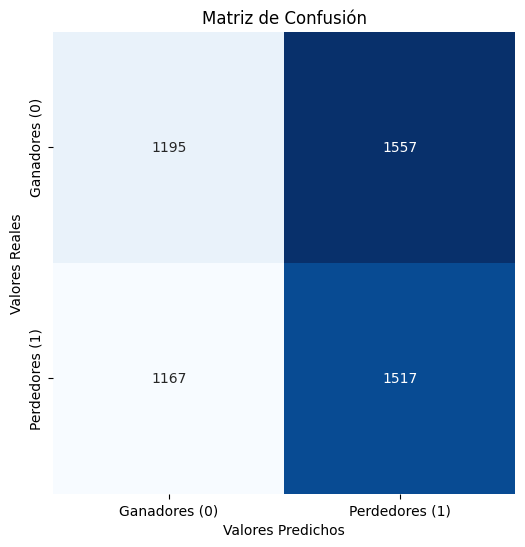

In [ ]:
#@title Grafica de la Matriz de confusión para el periodo 3:
# Crear una figura
plt.figure(figsize=(8, 6))

# Utilizar Seaborn para crear un mapa de calor (heatmap) de la matriz de confusión
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=["Ganadores (0)", "Perdedores (1)"],
            yticklabels=["Ganadores (0)", "Perdedores (1)"])

# Agregar etiquetas
plt.xlabel('Valores Predichos')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión')

# Mostrar el mapa de calor
plt.show()

##Prediccón Regresión Lineal

###Periodo 1:

In [ ]:
# @title Codigo Periodo 1:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Entrenar el modelo de regresión lineal
model = LinearRegression()
model.fit(X_resampled, y_resampled)

# Predecir los resultados
prediccion = model.predict(X_resampled)

# Redondear las predicciones a 0 o 1 para clasificación
prediccion_clasificacion = np.round(prediccion)
# Redondear las predicciones a 0 o 1 para clasificación
prediccion_clasificacion = np.round(prediccion)
prediccion_clasificacion

array([0., 0., 0., ..., 1., 1., 1.])

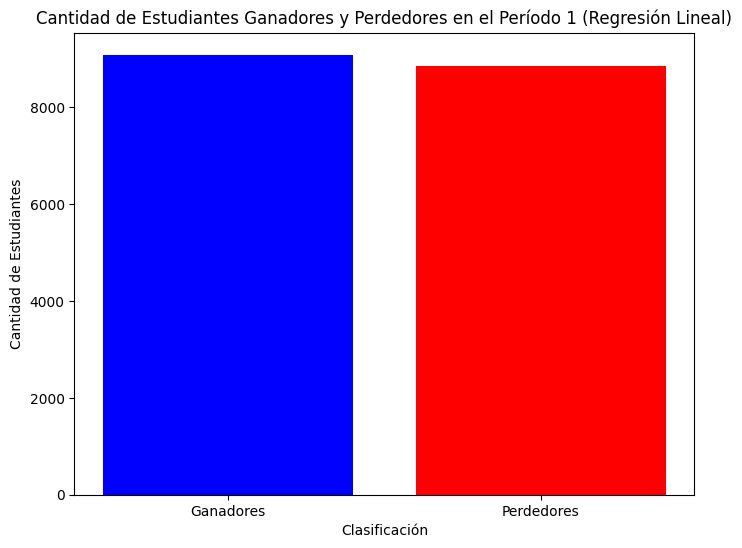

In [ ]:
#@title Grafica Periodo 1:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion_clasificacion == 0)
cantidad_perdedores = np.sum(prediccion_clasificacion == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores", "Perdedores"]
cantidad_estudiantes = [cantidad_ganadores, cantidad_perdedores]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(8, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 (Regresión Lineal)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 1:
# Calcular la matriz de confusión
cm = confusion_matrix(y_resampled, prediccion_clasificacion)

# Calcular otras métricas de evaluación
report = classification_report(y_resampled, prediccion_clasificacion)
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.86      0.87      0.86      8975
           1       0.87      0.86      0.86      8975

    accuracy                           0.86     17950
   macro avg       0.86      0.86      0.86     17950
weighted avg       0.86      0.86      0.86     17950



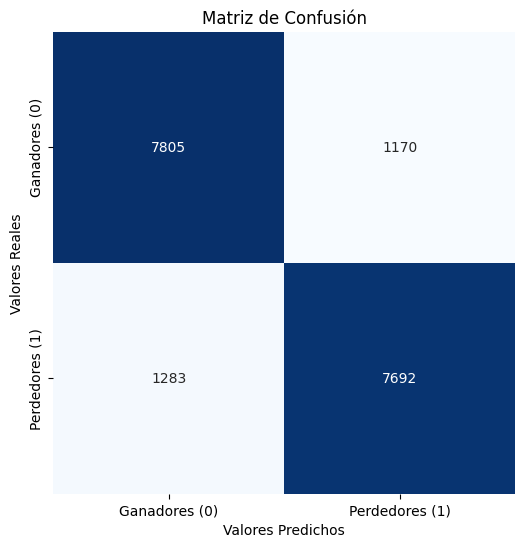

In [ ]:
#@title Grafica de la Matriz de confusión para el periodo 1:
# Crear una figura
plt.figure(figsize=(8, 6))

# Utilizar Seaborn para crear un mapa de calor (heatmap) de la matriz de confusión
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=["Ganadores (0)", "Perdedores (1)"],
            yticklabels=["Ganadores (0)", "Perdedores (1)"])

# Agregar etiquetas
plt.xlabel('Valores Predichos')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión')

# Mostrar el mapa de calor
plt.show()

###Periodo 2:

In [ ]:
# @title Codigo Periodo 2:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Entrenar el modelo de regresión lineal
model = LinearRegression()
model.fit(X_resampled, y_resampled)

# Predecir los resultados
prediccion = model.predict(X_resampled)

# Redondear las predicciones a 0 o 1 para clasificación
prediccion_clasificacion = np.round(prediccion)
# Redondear las predicciones a 0 o 1 para clasificación
prediccion_clasificacion = np.round(prediccion)
prediccion_clasificacion

array([0., 0., 0., ..., 1., 1., 1.])

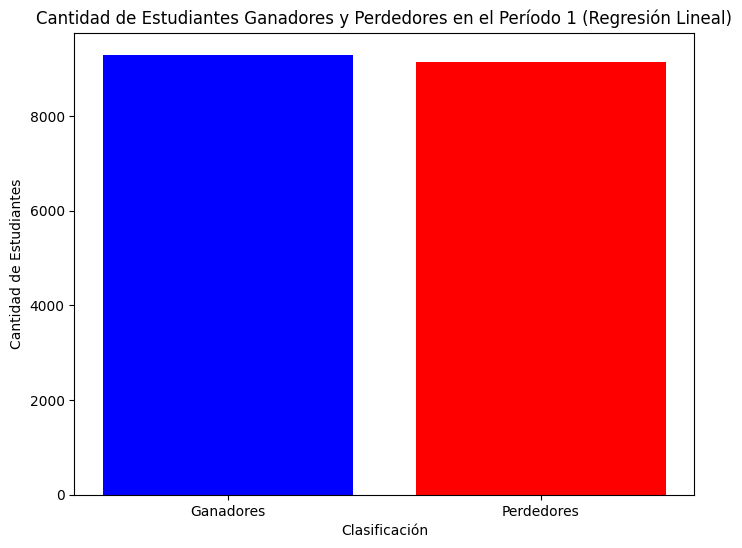

In [ ]:
#@title Grafica Periodo 2:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion_clasificacion == 0)
cantidad_perdedores = np.sum(prediccion_clasificacion == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores", "Perdedores"]
cantidad_estudiantes = [cantidad_ganadores, cantidad_perdedores]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(8, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 (Regresión Lineal)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 2:
# Calcular la matriz de confusión
cm = confusion_matrix(y_resampled, prediccion_clasificacion)

# Calcular otras métricas de evaluación
report = classification_report(y_resampled, prediccion_clasificacion)
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      9224
           1       0.85      0.85      0.85      9224

    accuracy                           0.85     18448
   macro avg       0.85      0.85      0.85     18448
weighted avg       0.85      0.85      0.85     18448



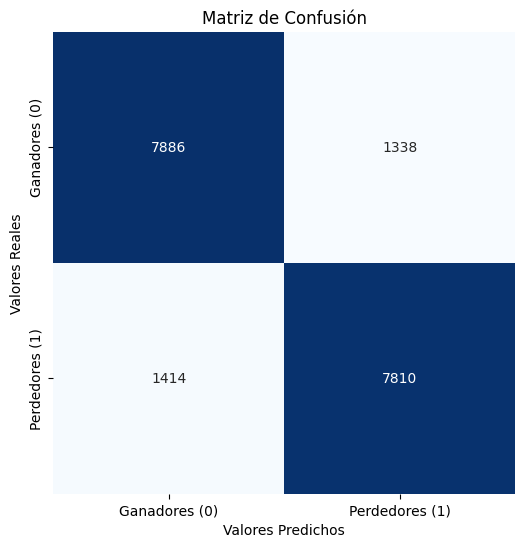

In [ ]:
#@title Grafica de la Matriz de confusión para el periodo 2:
# Crear una figura
plt.figure(figsize=(8, 6))

# Utilizar Seaborn para crear un mapa de calor (heatmap) de la matriz de confusión
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
            xticklabels=["Ganadores (0)", "Perdedores (1)"],
            yticklabels=["Ganadores (0)", "Perdedores (1)"])

# Agregar etiquetas
plt.xlabel('Valores Predichos')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión')

# Mostrar el mapa de calor
plt.show()

###Periodo 3:

In [ ]:
# @title Codigo Periodo 3:
# Separar los datos de entrada y salida
X_list = []
y_list_P1 = []  # Para PierdePeriodo1
y_list_P2 = []  # Para PierdePeriodo2
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y_P1 = data["PierdePeriodo1"]
    y_P2 = data["PierdePeriodo2"]
    X_list.append(X)
    y_list_P1.append(y_P1)
    y_list_P2.append(y_P2)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y_P1 = np.concatenate(y_list_P1, axis=0)
y_P2 = np.concatenate(y_list_P2, axis=0)

# Convertir el problema de regresión a clasificación
y_P1 = np.round(y_P1)
y_P2 = np.round(y_P2)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo1
smote_P1 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P1, y_resampled_P1 = smote_P1.fit_resample(X, y_P1)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo2
smote_P2 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P2, y_resampled_P2 = smote_P2.fit_resample(X, y_P2)

# Entrenar el modelo de regresión lineal para PierdePeriodo1
model_P1 = LinearRegression()
model_P1.fit(X_resampled_P1, y_resampled_P1)

# Entrenar el modelo de regresión lineal para PierdePeriodo2
model_P2 = LinearRegression()
model_P2.fit(X_resampled_P2, y_resampled_P2)

# Predecir los resultados para PierdePeriodo1
prediccion_P1 = model_P1.predict(X_resampled_P1)
prediccion_clasificacion_P1 = np.round(prediccion_P1)

# Predecir los resultados para PierdePeriodo2
prediccion_P2 = model_P2.predict(X_resampled_P2)
prediccion_clasificacion_P2 = np.round(prediccion_P2)

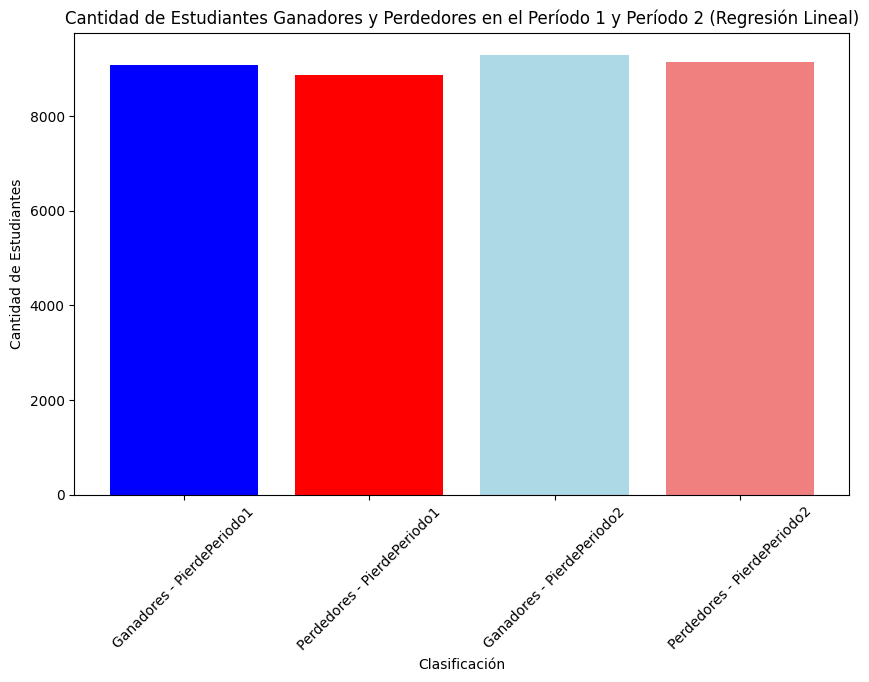

In [ ]:
#@title Grafica Periodo 3:
# Contar la cantidad de estudiantes ganadores y perdedores para PierdePeriodo1
cantidad_ganadores_P1 = np.sum(prediccion_clasificacion_P1 == 0)
cantidad_perdedores_P1 = np.sum(prediccion_clasificacion_P1 == 1)

# Contar la cantidad de estudiantes ganadores y perdedores para PierdePeriodo2
cantidad_ganadores_P2 = np.sum(prediccion_clasificacion_P2 == 0)
cantidad_perdedores_P2 = np.sum(prediccion_clasificacion_P2 == 1)

# Etiquetas para las barras
etiquetas = ["Ganadores - PierdePeriodo1", "Perdedores - PierdePeriodo1", "Ganadores - PierdePeriodo2", "Perdedores - PierdePeriodo2"]
cantidad_estudiantes = [cantidad_ganadores_P1, cantidad_perdedores_P1, cantidad_ganadores_P2, cantidad_perdedores_P2]

# Crear una figura para el gráfico de barras
plt.figure(figsize=(10, 6))

# Crear el gráfico de barras
plt.bar(etiquetas, cantidad_estudiantes, color=['blue', 'red', 'lightblue', 'lightcoral'])

# Etiquetar ejes y título
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 y Período 2 (Regresión Lineal)")

# Mostrar el gráfico de barras
plt.xticks(rotation=45)
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 3:

# Combinar las predicciones y etiquetas verdaderas para PierdePeriodo1 y PierdePeriodo2
predicciones = np.concatenate([prediccion_clasificacion_P1, prediccion_clasificacion_P2])
etiquetas_verdaderas = np.concatenate([y_resampled_P1, y_resampled_P2])

# Generar el informe de clasificación para ambos períodos
report = classification_report(etiquetas_verdaderas, predicciones)

# Imprimir el informe de clasificación combinado
print("Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:")
print(report)

Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:
              precision    recall  f1-score   support

           0       0.85      0.86      0.86     18199
           1       0.86      0.85      0.86     18199

    accuracy                           0.86     36398
   macro avg       0.86      0.86      0.86     36398
weighted avg       0.86      0.86      0.86     36398



##Predicción Árboles de Decisión

###Periodo 1

In [ ]:
#@title Codgio Periodo 1:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba (puedes ajustar la proporción según tus necesidades)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo de árboles de decisión
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

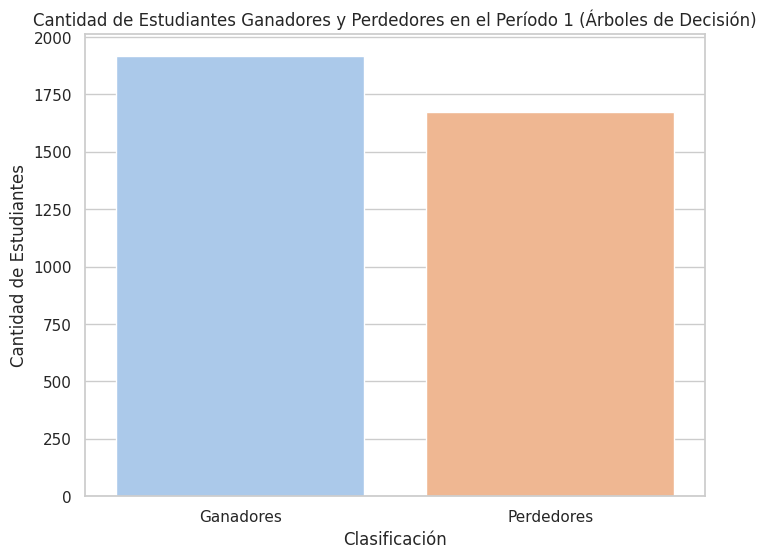

In [ ]:
#@title Grafica periodo 1:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 (Árboles de Decisión)")

# Mostrar el gráfico de barras
plt.show()


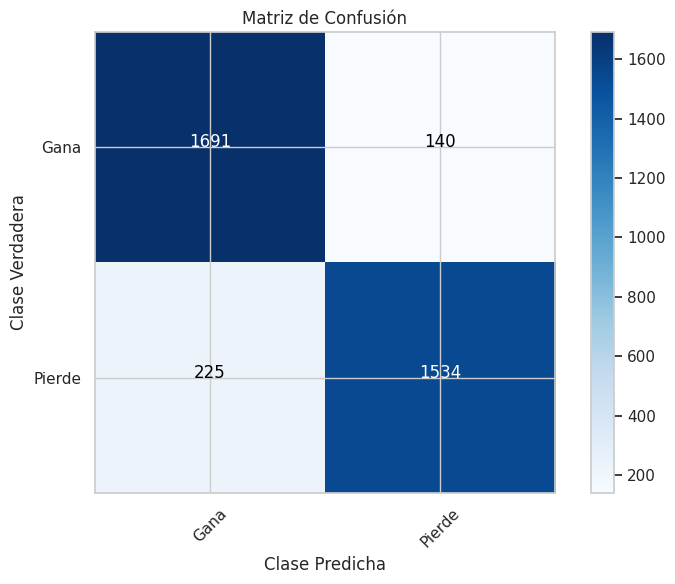

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()


In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.88      0.92      0.90      1831
           1       0.92      0.87      0.89      1759

    accuracy                           0.90      3590
   macro avg       0.90      0.90      0.90      3590
weighted avg       0.90      0.90      0.90      3590



###Periodo 2:

In [ ]:
#@title Codgio Periodo 2:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba (puedes ajustar la proporción según tus necesidades)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo de árboles de decisión
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

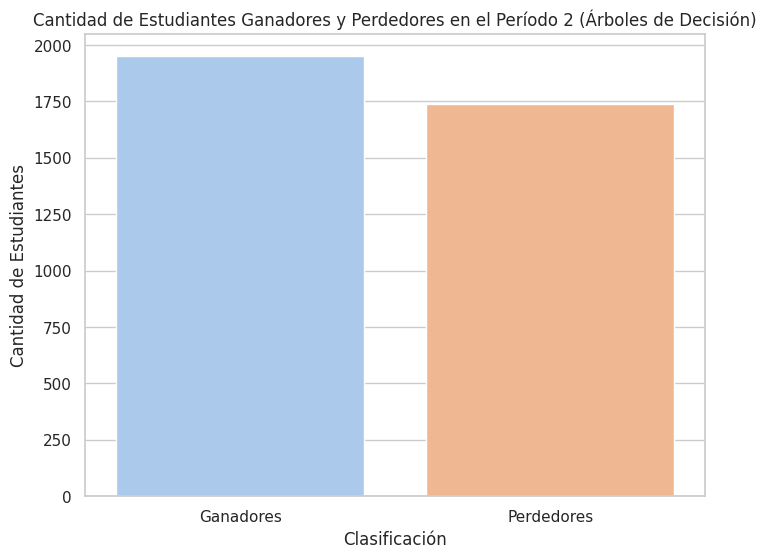

In [ ]:
#@title Grafica periodo 2:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 2 (Árboles de Decisión)")

# Mostrar el gráfico de barras
plt.show()

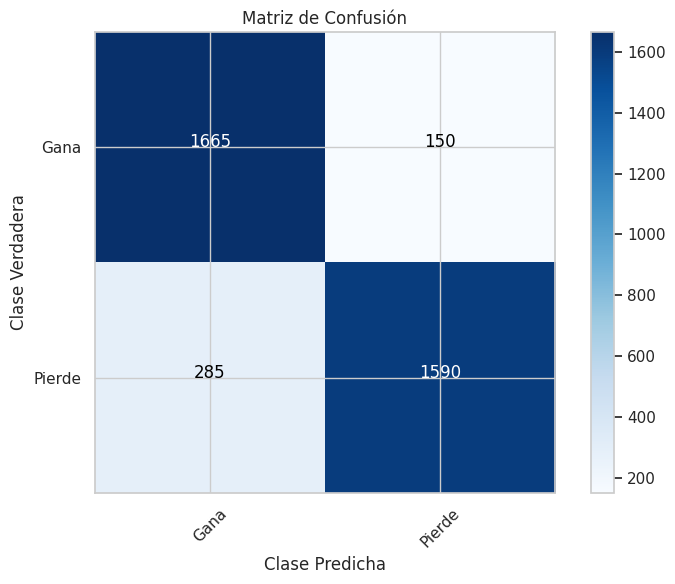

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88      1815
           1       0.91      0.85      0.88      1875

    accuracy                           0.88      3690
   macro avg       0.88      0.88      0.88      3690
weighted avg       0.88      0.88      0.88      3690



###Periodo 3:

In [ ]:
#@title Codgio Periodo 3:
# Separar los datos de entrada y salida
X_list = []
y_list_P1 = []  # Para PierdePeriodo1
y_list_P2 = []  # Para PierdePeriodo2
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y_P1 = data["PierdePeriodo1"]
    y_P2 = data["PierdePeriodo2"]
    X_list.append(X)
    y_list_P1.append(y_P1)
    y_list_P2.append(y_P2)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y_P1 = np.concatenate(y_list_P1, axis=0)
y_P2 = np.concatenate(y_list_P2, axis=0)

# Convertir el problema de regresión a clasificación
y_P1 = np.round(y_P1)
y_P2 = np.round(y_P2)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo1
smote_P1 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P1, y_resampled_P1 = smote_P1.fit_resample(X, y_P1)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo2
smote_P2 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P2, y_resampled_P2 = smote_P2.fit_resample(X, y_P2)

# Entrenar el modelo de regresión lineal para PierdePeriodo1
model_P1 = DecisionTreeClassifier()
model_P1.fit(X_resampled_P1, y_resampled_P1)

# Entrenar el modelo de regresión lineal para PierdePeriodo2
model_P2 = DecisionTreeClassifier()
model_P2.fit(X_resampled_P2, y_resampled_P2)

# Predecir los resultados para PierdePeriodo1
prediccion_P1 = model_P1.predict(X_resampled_P1)
prediccion_clasificacion_P1 = np.round(prediccion_P1)

# Predecir los resultados para PierdePeriodo2
prediccion_P2 = model_P2.predict(X_resampled_P2)
prediccion_clasificacion_P2 = np.round(prediccion_P2)

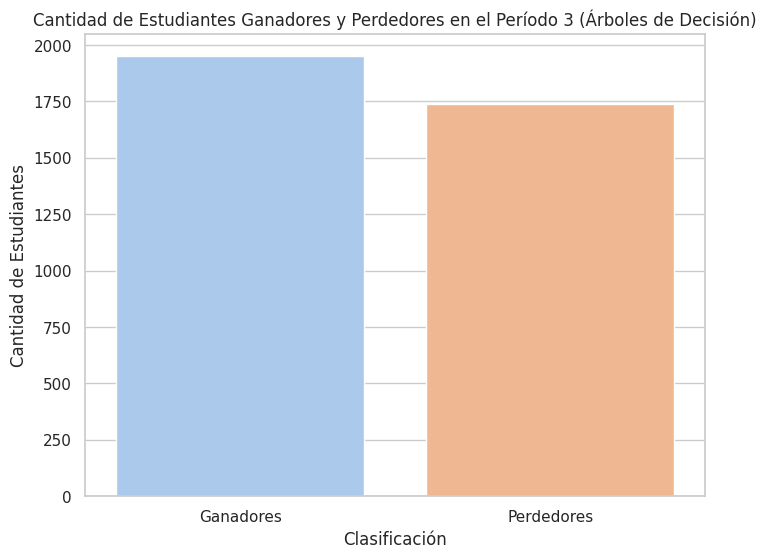

In [ ]:
#@title Grafica periodo 3:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 3 (Árboles de Decisión)")

# Mostrar el gráfico de barras
plt.show()

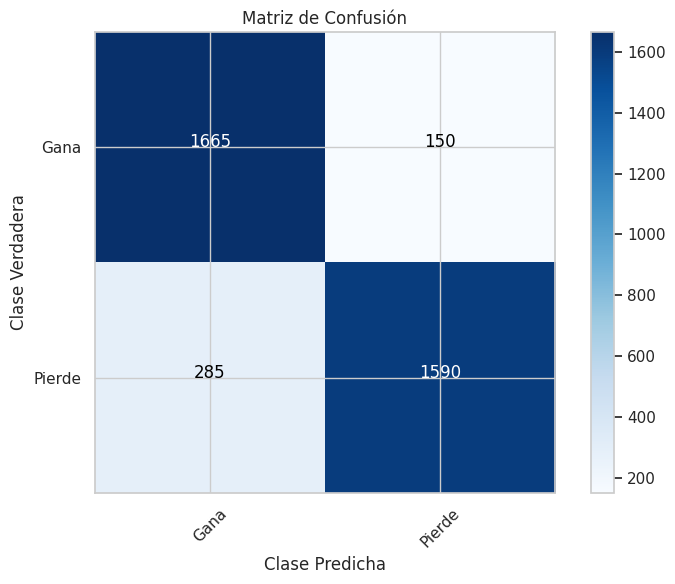

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 3:

# Combinar las predicciones y etiquetas verdaderas para PierdePeriodo1 y PierdePeriodo2
predicciones = np.concatenate([prediccion_clasificacion_P1, prediccion_clasificacion_P2])
etiquetas_verdaderas = np.concatenate([y_resampled_P1, y_resampled_P2])

# Generar el informe de clasificación para ambos períodos
report = classification_report(etiquetas_verdaderas, predicciones)

# Imprimir el informe de clasificación combinado
print("Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:")
print(report)

Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:
              precision    recall  f1-score   support

           0       0.92      0.94      0.93     18199
           1       0.94      0.91      0.93     18199

    accuracy                           0.93     36398
   macro avg       0.93      0.93      0.93     36398
weighted avg       0.93      0.93      0.93     36398



##KNN

###Periodo 1:

In [ ]:
#@title Codigo KNN:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba (puedes ajustar la proporción según tus necesidades)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo KNN con k=2
model = KNeighborsClassifier(n_neighbors=2)
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

In [ ]:
#@title Grafica periodo 1:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 (KNN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

###Periodo 2:

In [ ]:
#@title Codigo Periodo 2:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo de KNN
model = KNeighborsClassifier(n_neighbors=2)
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

In [ ]:
#@title Grafica periodo 2:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 2 (KNN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

###Periodo 3:

In [ ]:
#@title Codgio Periodo 3:
# Separar los datos de entrada y salida
X_list = []
y_list_P1 = []  # Para PierdePeriodo1
y_list_P2 = []  # Para PierdePeriodo2
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y_P1 = data["PierdePeriodo1"]
    y_P2 = data["PierdePeriodo2"]
    X_list.append(X)
    y_list_P1.append(y_P1)
    y_list_P2.append(y_P2)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y_P1 = np.concatenate(y_list_P1, axis=0)
y_P2 = np.concatenate(y_list_P2, axis=0)

# Convertir el problema de regresión a clasificación
y_P1 = np.round(y_P1)
y_P2 = np.round(y_P2)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo1
smote_P1 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P1, y_resampled_P1 = smote_P1.fit_resample(X, y_P1)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo2
smote_P2 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P2, y_resampled_P2 = smote_P2.fit_resample(X, y_P2)

# Entrenar el modelo de KNN para PierdePeriodo1
model_P1 = KNeighborsClassifier(n_neighbors=2)
model_P1.fit(X_resampled_P1, y_resampled_P1)

# Entrenar el modelo de KNN para PierdePeriodo2
model_P2 = KNeighborsClassifier(n_neighbors=2)
model_P2.fit(X_resampled_P2, y_resampled_P2)

# Predecir los resultados para PierdePeriodo1
prediccion_P1 = model_P1.predict(X_resampled_P1)
prediccion_clasificacion_P1 = np.round(prediccion_P1)

# Predecir los resultados para PierdePeriodo2
prediccion_P2 = model_P2.predict(X_resampled_P2)
prediccion_clasificacion_P2 = np.round(prediccion_P2)

In [ ]:
#@title Grafica periodo 3:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 3 (KNN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 3:

# Combinar las predicciones y etiquetas verdaderas para PierdePeriodo1 y PierdePeriodo2
predicciones = np.concatenate([prediccion_clasificacion_P1, prediccion_clasificacion_P2])
etiquetas_verdaderas = np.concatenate([y_resampled_P1, y_resampled_P2])

# Generar el informe de clasificación para ambos períodos
report = classification_report(etiquetas_verdaderas, predicciones)

# Imprimir el informe de clasificación combinado
print("Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:")
print(report)

##ANN

###Periodo 1:

In [ ]:
#@title Codigo ANN:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba (puedes ajustar la proporción según tus necesidades)
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo ANN
model = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

In [ ]:
#@title Grafica ANN:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores])
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 1 (ANN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

###Periodo 2:

In [ ]:
#@title Codigo Periodo 2:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Entrenar el modelo de ANN
model = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predecir los resultados en el conjunto de prueba
prediccion = model.predict(X_test)

In [ ]:
#@title Grafica periodo 2:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 2 (ANN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de clasificación
# Calcular el informe de clasificación
report = classification_report(y_test, prediccion)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(report)

###Periodo 3:

In [ ]:
#@title Codgio Periodo 3:
# Separar los datos de entrada y salida
X_list = []
y_list_P1 = []  # Para PierdePeriodo1
y_list_P2 = []  # Para PierdePeriodo2
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y_P1 = data["PierdePeriodo1"]
    y_P2 = data["PierdePeriodo2"]
    X_list.append(X)
    y_list_P1.append(y_P1)
    y_list_P2.append(y_P2)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y_P1 = np.concatenate(y_list_P1, axis=0)
y_P2 = np.concatenate(y_list_P2, axis=0)

# Convertir el problema de regresión a clasificación
y_P1 = np.round(y_P1)
y_P2 = np.round(y_P2)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo1
smote_P1 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P1, y_resampled_P1 = smote_P1.fit_resample(X, y_P1)

# Aplicar SMOTE para equilibrar las clases en PierdePeriodo2
smote_P2 = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled_P2, y_resampled_P2 = smote_P2.fit_resample(X, y_P2)

# Entrenar el modelo de KNN para PierdePeriodo1
model_P1 = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
model_P1.fit(X_resampled_P1, y_resampled_P1)

# Entrenar el modelo de KNN para PierdePeriodo2
model_P2 = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
model_P2.fit(X_resampled_P2, y_resampled_P2)

# Predecir los resultados para PierdePeriodo1
prediccion_P1 = model_P1.predict(X_resampled_P1)
prediccion_clasificacion_P1 = np.round(prediccion_P1)

# Predecir los resultados para PierdePeriodo2
prediccion_P2 = model_P2.predict(X_resampled_P2)
prediccion_clasificacion_P2 = np.round(prediccion_P2)

In [ ]:
#@title Grafica periodo 3:
# Contar la cantidad de estudiantes ganadores y perdedores
cantidad_ganadores = np.sum(prediccion == 0)
cantidad_perdedores = np.sum(prediccion == 1)

# Crear un gráfico de barras utilizando seaborn
sns.set(style="whitegrid")
plt.figure(figsize=(8, 6))
sns.barplot(x=["Ganadores", "Perdedores"], y=[cantidad_ganadores, cantidad_perdedores], palette="pastel")
plt.xlabel("Clasificación")
plt.ylabel("Cantidad de Estudiantes")
plt.title("Cantidad de Estudiantes Ganadores y Perdedores en el Período 3 (ANN)")

# Mostrar el gráfico de barras
plt.show()

In [ ]:
#@title Grafica Matriz de confusión
# Crear la matriz de confusión
cm = confusion_matrix(y_test, prediccion)

# Etiquetas para las clases
etiquetas_clases = ["Gana", "Pierde"]

# Crear una figura para el gráfico de la matriz de confusión
plt.figure(figsize=(8, 6))

# Crear el gráfico de la matriz de confusión
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Matriz de Confusión")
plt.colorbar()

tick_marks = np.arange(len(etiquetas_clases))
plt.xticks(tick_marks, etiquetas_clases, rotation=45)
plt.yticks(tick_marks, etiquetas_clases)

for i in range(len(etiquetas_clases)):
    for j in range(len(etiquetas_clases)):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > cm.max() / 2. else "black")

plt.ylabel('Clase Verdadera')
plt.xlabel('Clase Predicha')
plt.tight_layout()

# Mostrar el gráfico de la matriz de confusión
plt.show()

In [ ]:
#@title Informe de Clasificación del periodo 3:

# Combinar las predicciones y etiquetas verdaderas para PierdePeriodo1 y PierdePeriodo2
predicciones = np.concatenate([prediccion_clasificacion_P1, prediccion_clasificacion_P2])
etiquetas_verdaderas = np.concatenate([y_resampled_P1, y_resampled_P2])

# Generar el informe de clasificación para ambos períodos
report = classification_report(etiquetas_verdaderas, predicciones)

# Imprimir el informe de clasificación combinado
print("Informe de Clasificación para PierdePeriodo1 y PierdePeriodo2:")
print(report)

##DNN

###Periodo 1:

In [ ]:
#@title Codigo Periodo 1:
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import accuracy_score
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo1"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Crear un modelo DNN en TensorFlow
model = keras.Sequential([
    keras.layers.Dense(100, activation='relu', input_shape=(X_train.shape[1],)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')  # Capa de salida para clasificación binaria
])

# Compilar el modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entrenar el modelo DNN
model.fit(X_train, y_train, epochs=50, batch_size=64, verbose=1)

# Evaluar el modelo en el conjunto de prueba
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Exactitud en el conjunto de prueba:", test_accuracy)

# Predecir los resultados en el conjunto de prueba
predicciones = model.predict(X_test)
predicciones_binarias = (predicciones > 0.5).astype(int)

# Calcular la exactitud de las predicciones
exactitud = accuracy_score(y_test, predicciones_binarias)
print("Exactitud de las predicciones:", exactitud)


Epoch 1/50
225/225 [==============================] - 2s 3ms/step - loss: 0.4836 - accuracy: 0.7932
Epoch 2/50
225/225 [==============================] - 1s 3ms/step - loss: 0.3990 - accuracy: 0.8602
Epoch 3/50
225/225 [==============================] - 1s 3ms/step - loss: 0.3918 - accuracy: 0.8634
Epoch 4/50
225/225 [==============================] - 1s 3ms/step - loss: 0.3900 - accuracy: 0.8599
Epoch 5/50
225/225 [==============================] - 1s 3ms/step - loss: 0.3862 - accuracy: 0.8636
Epoch 6/50
225/225 [==============================] - 1s 2ms/step - loss: 0.3829 - accuracy: 0.8665
Epoch 7/50
225/225 [==============================] - 1s 3ms/step - loss: 0.3812 - accuracy: 0.8692
Epoch 8/50
225/225 [==============================] - 1s 2ms/step - loss: 0.3791 - accuracy: 0.8685
Epoch 9/50
225/225 [==============================] - 1s 2ms/step - loss: 0.3759 - accuracy: 0.8694
Epoch 10/50
225/225 [==============================] - 1s 2ms/step - loss: 0.3746 - accuracy: 0.8693

In [ ]:
# Predecir los resultados en el conjunto de prueba
predicciones = model.predict(X_test)
predicciones_binarias = (predicciones > 0.5).astype(int)

# Calcular el informe de clasificación
informe_clasificacion = classification_report(y_test, predicciones_binarias)

# Imprimir el informe de clasificación
print("Informe de Clasificación:")
print(informe_clasificacion)


113/113 [==============================] - 1s 5ms/step
Informe de Clasificación:
              precision    recall  f1-score   support

           0       0.87      0.93      0.90      1831
           1       0.92      0.85      0.88      1759

    accuracy                           0.89      3590
   macro avg       0.89      0.89      0.89      3590
weighted avg       0.89      0.89      0.89      3590



###Periodo 2:

In [ ]:
#@title Codigo Periodo 2:
# Separar los datos de entrada y salida
X_list = []
y_list = []
for data in data_list:
    X = data[["Periodo1", "Periodo2"]]
    y = data["PierdePeriodo2"]
    X_list.append(X)
    y_list.append(y)

# Combinar las matrices de datos
X = np.concatenate(X_list, axis=0)
y = np.concatenate(y_list, axis=0)

# Convertir el problema de regresión a clasificación
y = np.round(y)

# Aplicar SMOTE para equilibrar las clases
smote = SMOTE(sampling_strategy='auto', random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)

# Dividir los datos en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Crear un modelo DNN en TensorFlow
model = keras.Sequential([
    keras.layers.Dense(100, activation='relu', input_shape=(X_train.shape[1],)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')  # Capa de salida para clasificación binaria
])

# Compilar el modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entrenar el modelo DNN
model.fit(X_train, y_train, epochs=50, batch_size=64, verbose=1)

# Evaluar el modelo en el conjunto de prueba
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Exactitud en el conjunto de prueba:", test_accuracy)

# Predecir los resultados en el conjunto de prueba
predicciones = model.predict(X_test)
predicciones_binarias = (predicciones > 0.5).astype(int)

# Calcular la exactitud de las predicciones
exactitud = accuracy_score(y_test, predicciones_binarias)
print("Exactitud de las predicciones:", exactitud)

#**Validación de los modelos usando los datos del periodo 1 con el periodo 2(Regresión Logistica, Regresión Lineal, Árboles de Decisión, KNN, ANN y DNN)**

##**Predicción Regresión Logistica usando los datos entrenados de periodo 1 y validando el modelo con las notas del periodo 2**

###Regresión Logistica

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de regresión logística en los datos equilibrados del "Periodo 1"
model = LogisticRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Evaluar el rendimiento en el "Periodo 2"

accuracy_periodo2 = accuracy_score(y_resampled_periodo2, prediccion_periodo2)
report_periodo2 = classification_report(y_resampled_periodo2, prediccion_periodo2)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2, prediccion_periodo2)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)

Accuracy en Periodo 2: 0.6020164787510841
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.59      0.68      0.63      9224
           1       0.62      0.52      0.57      9224

    accuracy                           0.60     18448
   macro avg       0.60      0.60      0.60     18448
weighted avg       0.60      0.60      0.60     18448



In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de regresión logística en el conjunto de entrenamiento
model = LogisticRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion)
report_validacion = classification_report(y_valid, prediccion_validacion)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.65
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.64      0.74      0.69       156
           1       0.66      0.55      0.60       144

    accuracy                           0.65       300
   macro avg       0.65      0.65      0.64       300
weighted avg       0.65      0.65      0.65       300



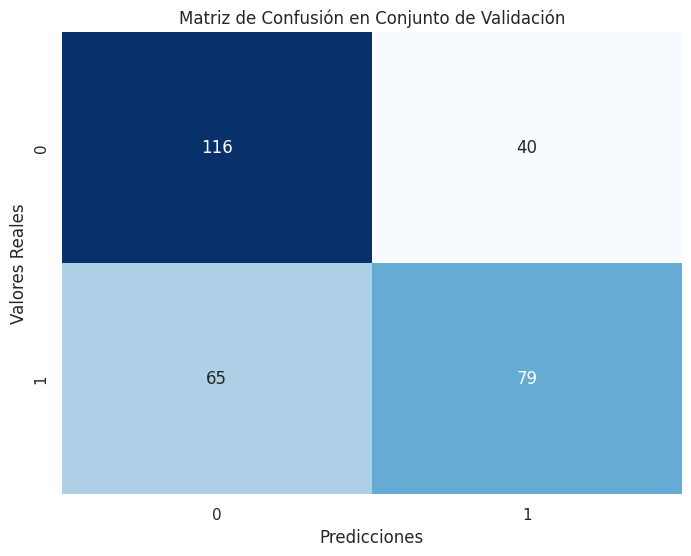

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

##**Predicción Regresión Lineal usando los datos entrenados de periodo 1 y validando el modelo con las notas del periodo 2**

###Regresión Lineal

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de regresión logística en los datos equilibrados del "Periodo 1"
model = LinearRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Convertir los valores continuos del conjunto de datos de validación del periodo 2 en valores binarios
y_resampled_periodo2_binario = np.where(y_resampled_periodo2 > 0.5, 1, 0)
# Convertir los valores continuos de la variable `prediccion_periodo2` en valores binarios
prediccion_periodo2_binario = np.where(prediccion_periodo2 > 0.5, 1, 0)
# Evaluar el rendimiento en el "Periodo 2"
accuracy_periodo2 = accuracy_score(y_resampled_periodo2_binario, prediccion_periodo2_binario)
report_periodo2 = classification_report(y_resampled_periodo2_binario, prediccion_periodo2_binario)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2_binario, prediccion_periodo2_binario)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)


Accuracy en Periodo 2: 0.5963248048568951
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.58      0.69      0.63      9224
           1       0.62      0.50      0.56      9224

    accuracy                           0.60     18448
   macro avg       0.60      0.60      0.59     18448
weighted avg       0.60      0.60      0.59     18448



In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de regresión logística en el conjunto de entrenamiento
model = LinearRegression()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Convertir los valores continuos de la variable `prediccion_validacion` en valores binarios
prediccion_validacion_binario = np.where(prediccion_validacion > 0.5, 1, 0)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion_binario)
report_validacion = classification_report(y_valid, prediccion_validacion_binario)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.6433333333333333
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.60      0.73      0.66       142
           1       0.70      0.57      0.63       158

    accuracy                           0.64       300
   macro avg       0.65      0.65      0.64       300
weighted avg       0.65      0.64      0.64       300



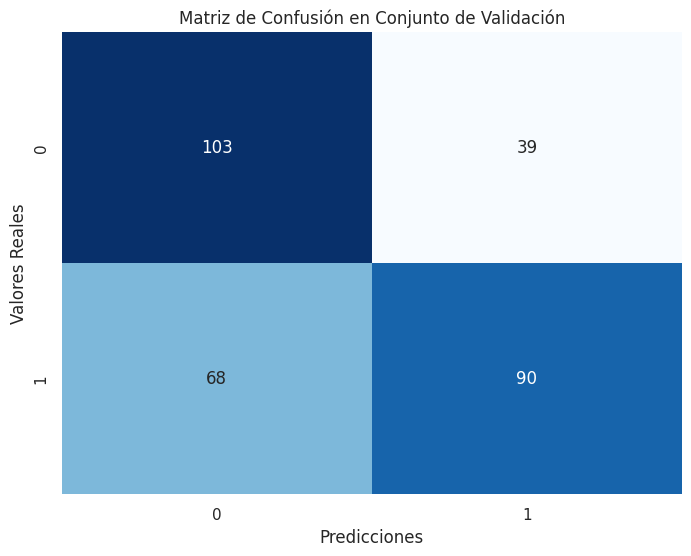

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion_binario)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

##**Predicción Árboles de Decisión usando los datos entrenados de periodo 1 y validando el modelo con las notas del periodo 2**

###Árboles de Decisión

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de Arboles de decisión en los datos equilibrados del "Periodo 1"
model = DecisionTreeClassifier()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Convertir los valores continuos del conjunto de datos de validación del periodo 2 en valores binarios
y_resampled_periodo2_binario = np.where(y_resampled_periodo2 > 0.5, 1, 0)
# Convertir los valores continuos de la variable `prediccion_periodo2` en valores binarios
prediccion_periodo2_binario = np.where(prediccion_periodo2 > 0.5, 1, 0)
# Evaluar el rendimiento en el "Periodo 2"
accuracy_periodo2 = accuracy_score(y_resampled_periodo2_binario, prediccion_periodo2_binario)
report_periodo2 = classification_report(y_resampled_periodo2_binario, prediccion_periodo2_binario)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2_binario, prediccion_periodo2_binario)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)


Accuracy en Periodo 2: 0.6217476149176062
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.60      0.74      0.66      9224
           1       0.66      0.50      0.57      9224

    accuracy                           0.62     18448
   macro avg       0.63      0.62      0.62     18448
weighted avg       0.63      0.62      0.62     18448



In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de Arboles de decisión en el conjunto de entrenamiento
model = DecisionTreeClassifier()
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion)
report_validacion = classification_report(y_valid, prediccion_validacion)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.65
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.63      0.77      0.69       153
           1       0.69      0.52      0.59       147

    accuracy                           0.65       300
   macro avg       0.66      0.65      0.64       300
weighted avg       0.66      0.65      0.64       300



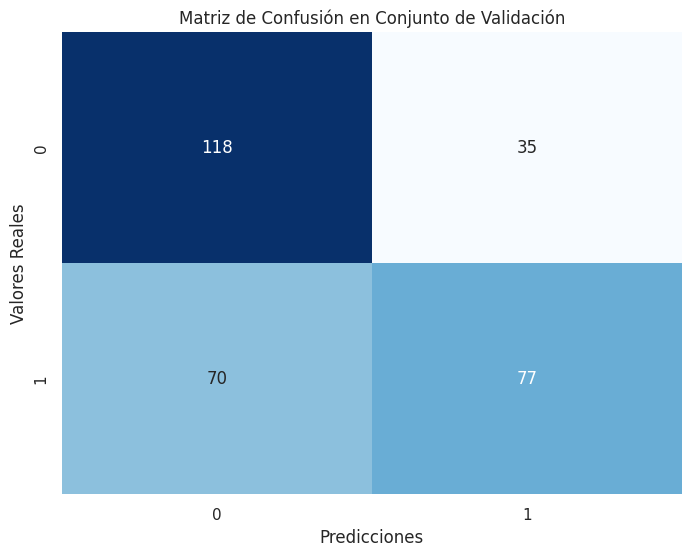

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

##**Predicción KNN**

###KNN

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de KNN en los datos equilibrados del "Periodo 1"
model = KNeighborsClassifier(n_neighbors=2)
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Evaluar el rendimiento en el "Periodo 2"

accuracy_periodo2 = accuracy_score(y_resampled_periodo2, prediccion_periodo2)
report_periodo2 = classification_report(y_resampled_periodo2, prediccion_periodo2)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2, prediccion_periodo2)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)

Accuracy en Periodo 2: 0.6027211621856028
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.58      0.76      0.66      9224
           1       0.65      0.44      0.53      9224

    accuracy                           0.60     18448
   macro avg       0.61      0.60      0.59     18448
weighted avg       0.61      0.60      0.59     18448



In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de regresión logística en el conjunto de entrenamiento
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion)
report_validacion = classification_report(y_valid, prediccion_validacion)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.66
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.65      0.82      0.72       163
           1       0.68      0.47      0.56       137

    accuracy                           0.66       300
   macro avg       0.67      0.65      0.64       300
weighted avg       0.66      0.66      0.65       300



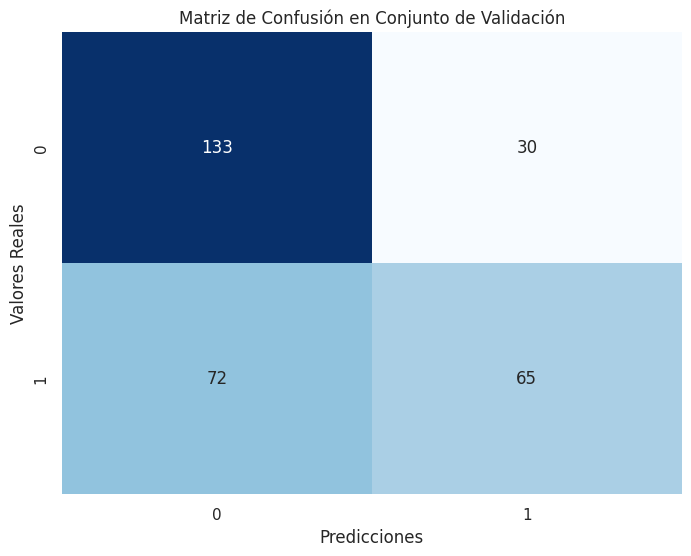

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

##**Predicción ANN**

###ANN

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Entrenar el modelo de ANN en los datos equilibrados del "Periodo 1"
model =  MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=1000, random_state=42)
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Evaluar el rendimiento en el "Periodo 2"

accuracy_periodo2 = accuracy_score(y_resampled_periodo2, prediccion_periodo2)
report_periodo2 = classification_report(y_resampled_periodo2, prediccion_periodo2)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2, prediccion_periodo2)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)

Accuracy en Periodo 2: 0.5872181266261925
Classification Report en Periodo 2:
               precision    recall  f1-score   support

           0       0.57      0.72      0.64      9224
           1       0.62      0.46      0.52      9224

    accuracy                           0.59     18448
   macro avg       0.59      0.59      0.58     18448
weighted avg       0.59      0.59      0.58     18448



In [ ]:
#@title Informe de clasificación de validación del periodo 1 con muestra de 300 estudiantes
# Selecciona una cantidad específica de datos para validación (por ejemplo, 300)
num_samples_for_validation = 300

# Dividir los datos en conjunto de entrenamiento y conjunto de validación
X_train, X_valid, y_train, y_valid = train_test_split(X_resampled_periodo2, y_resampled_periodo2, test_size=num_samples_for_validation)

# Entrenar el modelo de regresión logística en el conjunto de entrenamiento
model.fit(X_resampled_periodo1, y_resampled_periodo1)

# Realizar predicciones en el conjunto de validación
prediccion_validacion = model.predict(X_valid)

# Evaluar el rendimiento en el conjunto de validación
accuracy_validacion = accuracy_score(y_valid, prediccion_validacion)
report_validacion = classification_report(y_valid, prediccion_validacion)

print("Accuracy en Conjunto de Validación:", accuracy_validacion)
print("Classification Report en Conjunto de Validación:\n", report_validacion)

Accuracy en Conjunto de Validación: 0.5966666666666667
Classification Report en Conjunto de Validación:
               precision    recall  f1-score   support

           0       0.61      0.73      0.67       166
           1       0.56      0.43      0.49       134

    accuracy                           0.60       300
   macro avg       0.59      0.58      0.58       300
weighted avg       0.59      0.60      0.59       300



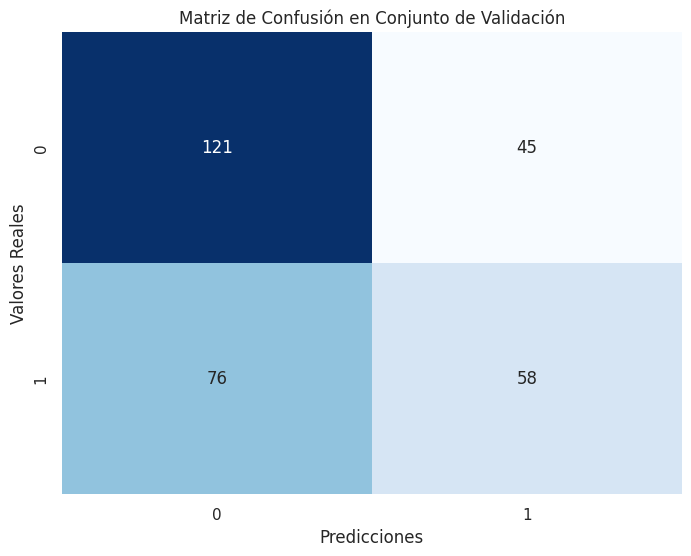

In [ ]:
#@title Matriz de confusion de los 300 estudiantes
# Crear y mostrar la matriz de confusión de manera gráfica
conf_matrix_validacion = confusion_matrix(y_valid, prediccion_validacion)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_validacion, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Conjunto de Validación')
plt.show()

##**Predicción DNN**

###DNN

In [ ]:
#@title Informe de clasificación de validación del periodo 1:
# Separar los datos de entrada y salida del "Periodo 1"
X_list_periodo1 = []
y_list_periodo1 = []

for data in data_list:
    X_periodo1 = data[["Periodo1", "Periodo2"]]
    y_periodo1 = data["PierdePeriodo1"]
    X_list_periodo1.append(X_periodo1)
    y_list_periodo1.append(y_periodo1)

# Combinar las matrices de datos del "Periodo 1"
X_periodo1 = np.concatenate(X_list_periodo1, axis=0)
y_periodo1 = np.concatenate(y_list_periodo1, axis=0)

# Aplicar SMOTE para abordar el desequilibrio de clases en el "Periodo 1"
smote = SMOTE(sampling_strategy='auto')
X_resampled_periodo1, y_resampled_periodo1 = smote.fit_resample(X_periodo1, y_periodo1)

# Crear un modelo DNN en TensorFlow
model = keras.Sequential([
    keras.layers.Dense(100, activation='relu', input_shape=(X_train.shape[1],)),
    keras.layers.Dense(50, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')  # Capa de salida para clasificación binaria
])

# Compilar el modelo
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Entrenar el modelo DNN
model.fit(X_train, y_train, epochs=50, batch_size=64, verbose=1)

# Validar con los datos del "Periodo 2"
X_list_periodo2 = []
y_list_periodo2 = []

for data in data_list:
    X_periodo2 = data[["Periodo1", "Periodo2"]]
    y_periodo2 = data["PierdePeriodo2"]
    X_list_periodo2.append(X_periodo2)
    y_list_periodo2.append(y_periodo2)

# Combinar las matrices de datos del "Periodo 2"
X_periodo2 = np.concatenate(X_list_periodo2, axis=0)
y_periodo2 = np.concatenate(y_list_periodo2, axis=0)
X_resampled_periodo2, y_resampled_periodo2 = smote.fit_resample(X_periodo2, y_periodo2)
# Realizar predicciones en los datos del "Periodo 2"
prediccion_periodo2 = model.predict(X_resampled_periodo2)

# Convertir los valores continuos de la variable `prediccion_periodo2` en valores binarios
prediccion_periodo2_binario = np.where(prediccion_periodo2 > 0.5, 1, 0)

# Evaluar el rendimiento en el "Periodo 2"
accuracy_periodo2 = accuracy_score(y_resampled_periodo2, prediccion_periodo2_binario)
report_periodo2 = classification_report(y_resampled_periodo2, prediccion_periodo2_binario)
conf_matrix_periodo2 = confusion_matrix(y_resampled_periodo2, prediccion_periodo2_binario)

print("Accuracy en Periodo 2:", accuracy_periodo2)
print("Classification Report en Periodo 2:\n", report_periodo2)

Epoch 1/50
284/284 [==============================] - 1s 2ms/step - loss: 0.4780 - accuracy: 0.7935
Epoch 2/50
284/284 [==============================] - 1s 2ms/step - loss: 0.4077 - accuracy: 0.8590
Epoch 3/50
284/284 [==============================] - 1s 2ms/step - loss: 0.4046 - accuracy: 0.8558
Epoch 4/50
284/284 [==============================] - 1s 2ms/step - loss: 0.3999 - accuracy: 0.8615
Epoch 5/50
284/284 [==============================] - 1s 2ms/step - loss: 0.3971 - accuracy: 0.8637
Epoch 6/50
284/284 [==============================] - 1s 2ms/step - loss: 0.3959 - accuracy: 0.8604
Epoch 7/50
284/284 [==============================] - 1s 2ms/step - loss: 0.3919 - accuracy: 0.8653
Epoch 8/50
284/284 [==============================] - 1s 3ms/step - loss: 0.3890 - accuracy: 0.8659
Epoch 9/50
284/284 [==============================] - 1s 3ms/step - loss: 0.3864 - accuracy: 0.8675
Epoch 10/50
284/284 [==============================] - 1s 3ms/step - loss: 0.3845 - accuracy: 0.8702

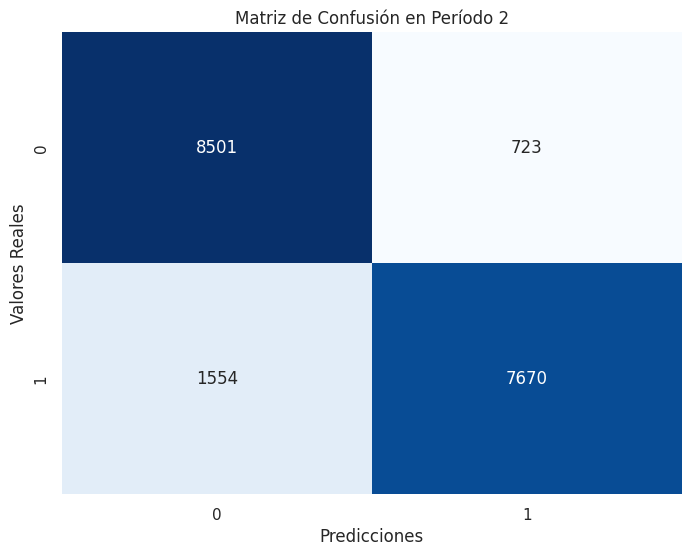

In [ ]:
#@title Matriz de confusion
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_periodo2, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicciones')
plt.ylabel('Valores Reales')
plt.title('Matriz de Confusión en Período 2')
plt.show()